# Retail Customer Sales - Exploratory Data Analysis

**Student:** Arpit Gupta  
**Project:** MCA Project 1  Exploratory Data Analysis  
**Admission No:** 2026M01410140  

In this notebook I explore the retail sales dataset, check for data problems, clean the data, and answer a few business questions using Python.

## 1. Loading the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi':90,'axes.titleweight':'bold'})
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.max_columns = 30

raw = pd.read_csv('retail_customer_sales_dataset.csv')
df = raw.copy()         
print('Shape:', raw.shape)
raw.head()

Shape: (7084, 24)


,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.00,Male,"62,828.52",West,Gujarat,Surat,Consumer,Grocery,Honey Jar,3,887.94,0.32,"1,811.40","1,204.47",606.93,Debit Card,Standard,3.00,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.00,Male,"50,952.64",North,Haryana,Gurugram,Home Office,Electronics,USB-C Hub,2,"14,309.96",0.18,"23,468.33","17,137.06","6,331.27",Credit Card,Standard,3.00,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.00,Male,"60,476.00",East,Jharkhand,Ranchi,Consumer,Clothing,Winter Jacket,4,710.95,0.09,"2,587.86","1,577.83","1,010.03",Debit Card,Express,3.00,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.00,Male,"41,516.94",West,Gujarat,Surat,Home Office,Grocery,Olive Oil 1L,4,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.00,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.00,Female,"95,727.49",north,Haryana,Gurugram,Consumer,Electronics,Laptop Stand,1,"10,542.13",0.21,"8,328.28","5,528.47","2,799.81",UPI,Express,1.00,Low,No


In [2]:
raw.tail()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
7079,TXN201768,CUST10870,2024-10-22,2024-10-27,34.00,Male,"79,446.58",East,Odisha,Bhubaneswar,Corporate,Electronics,Laptop Stand,1,"5,395.38",0.09,"4,909.80","3,273.47","1,636.33",Net Banking,Express,2.00,Low,Yes
7080,TXN201737,CUST10314,2024-10-05,2024-10-14,50.00,Male,"21,796.92",East,West Bengal,Durgapur,Home Office,Clothing,Formal Shirt,3,"1,603.82",0.02,"4,715.23","2,923.68","1,791.55",Credit Card,Standard,4.00,High,No
7081,TXN203240,CUST10859,2024-06-04,2024-06-15,42.00,Male,"60,621.27",West,Gujarat,Surat,Consumer,Electronics,Laptop Stand,1,"11,519.59",0.22,"8,985.28","5,360.01","3,625.27",UPI,Standard,2.00,Medium,No
7082,TXN205305,CUST10829,2024-03-31,2024-04-08,32.00,Female,"42,178.47",South,Kerala,Kozhikode,Consumer,Clothing,Running Shoes,3,980.67,0.21,"2,324.19","1,812.17",512.02,UPI,Standard,4.00,High,No
7083,TXN204737,CUST10847,2024-10-18,2024-10-26,63.00,Male,"44,113.29",South,Kerala,Kozhikode,Consumer,Clothing,Denim Jacket,2,"3,727.59",0.30,"5,218.63","3,932.52","1,286.11",Debit Card,Standard,4.00,High,No


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7084 entries, 0 to 7083
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      7084 non-null   object 
 1   Customer_ID         7084 non-null   object 
 2   Order_Date          7084 non-null   object 
 3   Delivery_Date       6978 non-null   object 
 4   Age                 6942 non-null   float64
 5   Gender              7084 non-null   object 
 6   Income              6831 non-null   float64
 7   Region              7084 non-null   object 
 8   State               7084 non-null   object 
 9   City                7084 non-null   object 
 10  Customer_Segment    7084 non-null   object 
 11  Product_Category    7084 non-null   object 
 12  Product             7084 non-null   object 
 13  Quantity            7084 non-null   int64  
 14  Unit_Price          7084 non-null   float64
 15  Discount            7013 non-null   float64
 16  Sales 

I checked the first few rows and the column types before cleaning. The data has 7,084 rows and 24 columns. A few dates are stored as text, and missing values are present in age, income, discount, rating, delivery date, and satisfaction level.

## 2. Data quality checks

### 2.1 Missing values

,Missing,Missing_%
Customer_Rating,428,6.04
Income,253,3.57
Satisfaction_Level,179,2.53
Age,142,2.00
Delivery_Date,106,1.50
Discount,71,1.00


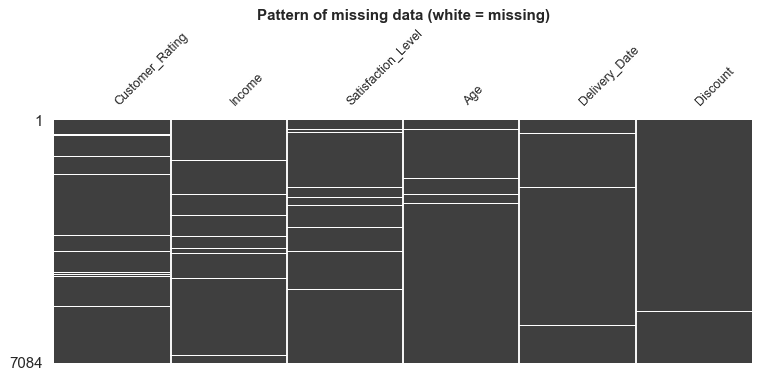

In [4]:
miss = pd.DataFrame({'Missing': raw.isna().sum(), 'Missing_%': raw.isna().mean()*100})
miss = miss[miss.Missing>0].sort_values('Missing', ascending=False)
display(miss)
import missingno as msno
msno.matrix(raw[miss.index], figsize=(10,3.5), sparkline=False, fontsize=10)
plt.title('Pattern of missing data (white = missing)'); plt.show()

The missing values are spread across six columns. The largest gap is in `Customer_Rating`, but it is only about 6%. Missingness does not appear to form a clear block or pattern.

### 2.2 Duplicate records

In [5]:
print('Exact duplicate rows            :', raw.duplicated().sum())
print('Duplicated Transaction_IDs       :', raw.Transaction_ID.duplicated().sum())
print('Unique Transaction_IDs           :', raw.Transaction_ID.nunique())
hidden = raw[raw.Transaction_ID.duplicated(keep=False) & ~raw.duplicated(keep=False)].sort_values('Transaction_ID')
print('Rows in hidden-duplicate pairs   :', len(hidden))
hidden[['Transaction_ID','Order_Date','Gender','Region','Satisfaction_Level']].head(8)

Exact duplicate rows            : 61
Duplicated Transaction_IDs       : 84
Unique Transaction_IDs           : 7000
Rows in hidden-duplicate pairs   : 46


,Transaction_ID,Order_Date,Gender,Region,Satisfaction_Level
1227,TXN200162,22/07/2024,Female,South,High
1386,TXN200162,2024-07-22,Female,South,High
3392,TXN200221,2023-06-23,female,West,NaN
6761,TXN200221,2023-06-23,Female,West,NaN
3719,TXN200275,30/06/2024,Male,NORTH,NaN
2682,TXN200275,30-Jun-2024,Male,North,NaN
1713,TXN200750,2024-02-11,female,Sth,Medium
2679,TXN200750,2024-02-11,Female,South,Medium


There are 61 exact duplicate rows and 84 repeated `Transaction_ID` values. The extra 23 repeated IDs are partly hidden by differences in spelling or date format, so standardisation is done before removing duplicates.

### 2.3 Check category spellings

In [6]:
for c in ['Gender','Region']:
    print(c, '->', raw[c].value_counts().to_dict(), '\n')
for c in ['Customer_Segment','Product_Category','Payment_Method','Delivery_Mode','Satisfaction_Level','Returned']:
    print(c, '->', raw[c].dropna().unique().tolist())

Gender -> {'Female': 3585, 'Male': 3232, 'female': 53, 'FEMALE': 53, 'male': 46, 'MALE': 44, 'M': 38, 'F': 33} 

Region -> {'West': 1783, 'East': 1754, 'South': 1741, 'North': 1647, 'east': 30, 'south': 24, 'north': 21, 'Sth': 20, 'WEST': 19, 'Nort': 17, 'west': 15, 'NORTH': 13} 

Customer_Segment -> ['Consumer', 'Home Office', 'Corporate']
Product_Category -> ['Grocery', 'Electronics', 'Clothing', 'Furniture', 'Office Supplies']
Payment_Method -> ['Debit Card', 'Credit Card', 'UPI', 'Cash on Delivery', 'Net Banking']
Delivery_Mode -> ['Standard', 'Express', 'Same-Day']
Satisfaction_Level -> ['Low', 'High', 'Medium']
Returned -> ['No', 'Yes']


Gender and region contain several different forms of the same category, such as `M/Male/male` and `Sth/South/south`. The remaining categorical columns look consistent.

### 2.4 Values outside a reasonable range

In [7]:
print('Age < 0           :', (raw.Age<0).sum(), raw.Age[raw.Age<0].tolist())
print('Age > 100         :', (raw.Age>100).sum(), raw.Age[raw.Age>100].tolist())
print('Discount < 0      :', (raw.Discount<0).sum(), raw.Discount[raw.Discount<0].tolist())
print('Discount > 0.5    :', (raw.Discount>0.5).sum(), raw.Discount[raw.Discount>0.5].tolist())
print('Quantity <= 0     :', (raw.Quantity<=0).sum())
print('Sales/Cost/Profit <= 0:', ((raw[['Sales','Cost','Profit']]<=0).sum()).to_dict())
print('Rating outside 1-5:', (~raw.Customer_Rating.dropna().between(1,5)).sum())
calc = raw.Quantity*raw.Unit_Price*(1-raw.Discount)
bad = (calc-raw.Sales).abs()/raw.Sales > 0.01
print('Rows where Sales formula breaks:', bad.sum())
raw.loc[bad,['Quantity','Unit_Price','Discount','Sales']]

Age < 0           : 3 [-5.0, -12.0, -1.0]
Age > 100         : 3 [180.0, 999.0, 150.0]
Discount < 0      : 2 [-0.2, -0.1]
Discount > 0.5    : 4 [2.0, 1.1, 1.5, 1.2]
Quantity <= 0     : 0
Sales/Cost/Profit <= 0: {'Sales': 0, 'Cost': 0, 'Profit': 0}
Rating outside 1-5: 0
Rows where Sales formula breaks: 6


,Quantity,Unit_Price,Discount,Sales
1196,3,"2,084.63",-0.20,"4,252.65"
2624,5,"12,394.56",2.00,"55,155.79"
3165,4,977.82,1.10,"3,598.38"
4174,4,"9,160.38",1.50,"33,343.78"
5410,3,324.04,-0.10,505.50
6693,5,"1,052.47",1.20,"5,209.73"


Six ages and six discount values are clearly wrong. The six unusual sales formula results also match those invalid discount rows, so the discount can be recovered from quantity, unit price, and sales instead of being guessed.

### 2.5 Date formats

In [8]:
pattern = lambda s: s.dropna().str.replace(r'[0-9]','9',regex=True).str.replace(r'[A-Za-z]+','Mon',regex=True)
print(pattern(raw.Order_Date).value_counts(), '\n')
print(pattern(raw.Delivery_Date).value_counts())

Order_Date
9999-99-99     6601
99-Mon-9999     161
99/99/9999      161
99-99-9999      161
Name: count, dtype: int64 

Delivery_Date
9999-99-99     6509
99-Mon-9999     158
99/99/9999      156
99-99-9999      155
Name: count, dtype: int64


The order and delivery dates use four formats. I use `dd/mm/yyyy` for slash dates and `mm-dd-yyyy` for hyphen dates because this gives valid dates and also keeps deliveries within a reasonable period after orders.

## 3. Cleaning the dataset

### 3.1 Standardising gender and region

In [9]:
df['Gender'] = df.Gender.str.strip().str.lower().map({'male':'Male','m':'Male','female':'Female','f':'Female'})
df['Region'] = df.Region.str.strip().str.lower().map({'north':'North','nort':'North','south':'South','sth':'South','east':'East','west':'West'})
print(df.Gender.value_counts(dropna=False).to_dict()); print(df.Region.value_counts(dropna=False).to_dict())

{'Female': 3724, 'Male': 3360}
{'West': 1817, 'South': 1785, 'East': 1784, 'North': 1698}


A direct mapping is used here because abbreviations such as `M`, `F`, `Nort`, and `Sth` cannot be fixed by changing case alone.

In [10]:
assert df.Gender.notna().all() and df.Region.notna().all()

### 3.2 Converting date columns

In [11]:
def parse_dates(s):
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    rules = [(r'^\d{4}-',        '%Y-%m-%d'),   # 2023-12-19
             (r'^\d\d/',         '%d/%m/%Y'),   # 19/12/2023
             (r'^\d\d-\d\d-',    '%m-%d-%Y'),   # 12-19-2023
             (r'^\d\d-[A-Za-z]', '%d-%b-%Y')]   # 19-Dec-2023
    for pat, fmt in rules:
        m = s.str.match(pat, na=False)
        out[m] = pd.to_datetime(s[m], format=fmt, errors='coerce')
    return out
df['Order_Date']    = parse_dates(raw.Order_Date)
df['Delivery_Date'] = parse_dates(raw.Delivery_Date)
print('Unparsed Order_Date:', df.Order_Date.isna().sum(), '| Order range:', df.Order_Date.min().date(), 'to', df.Order_Date.max().date())

Unparsed Order_Date: 0 | Order range: 2023-01-01 to 2024-12-31


### 3.3 Removing repeated transactions

In [12]:
before = len(df)
df['_nulls'] = df.isna().sum(axis=1)
df = (df.sort_values(['Transaction_ID','_nulls']).drop_duplicates('Transaction_ID', keep='first')
        .drop(columns='_nulls').sort_index().reset_index(drop=True))
print(f'Rows before: {before:,} | after: {len(df):,} | removed: {before-len(df)}')
assert df.Transaction_ID.is_unique

Rows before: 7,084 | after: 7,000 | removed: 84


The same transaction ID should not appear more than once. Where a repeated ID has a more complete copy, the copy with fewer missing values is kept.

### 3.4 Correcting invalid values

In [13]:
inv = (df.Discount<0)|(df.Discount>0.5)
df['Discount_Imputed'] = inv | df.Discount.isna()
implied = 1 - df.Sales/(df.Quantity*df.Unit_Price)
df.loc[df.Discount_Imputed,'Discount'] = implied[df.Discount_Imputed].round(2)
print('Discounts recovered:', df.Discount_Imputed.sum(), '| valid range now:', df.Discount.min(), '-', df.Discount.max())


df.loc[(df.Age<18)|(df.Age>100),'Age'] = np.nan
df['Age_Imputed'] = df.Age.isna()
df['Age'] = df.Age.fillna(df.groupby('Customer_ID').Age.transform('median'))
df['Age'] = df.Age.fillna(df.groupby('Customer_Segment').Age.transform('median'))   

df['Income_Imputed'] = df.Income.isna()
df['Income'] = df.Income.fillna(df.groupby('Customer_ID').Income.transform('median'))
df['Income'] = df.Income.fillna(df.groupby('Customer_Segment').Income.transform('median'))
print('Age min/max:', df.Age.min(), df.Age.max(), '| Remaining nulls Age/Income/Discount:', df[['Age','Income','Discount']].isna().sum().tolist())
print('Age imputed:', df.Age_Imputed.sum(), '| Income imputed:', df.Income_Imputed.sum())

Discounts recovered: 76 | valid range now: 0.0 - 0.5
Age min/max: 18.0 72.0 | Remaining nulls Age/Income/Discount: [0, 0, 0]
Age imputed: 146 | Income imputed: 245


For age and income, I first use the median for the customer's existing records. If that is not available, the customer segment median is used. Median is better for income because the income distribution is right-skewed.

### 3.5 Delivery date and remaining missing values

In [14]:
df['Delivery_Days'] = (df.Delivery_Date - df.Order_Date).dt.days
df['Delivery_Date_Error'] = df.Delivery_Days < 0
print('Delivery before order (data error):', df.Delivery_Date_Error.sum())
print('Delivery_Date missing:', df.Delivery_Date.isna().sum())

df.loc[df.Delivery_Date_Error, ['Delivery_Date','Delivery_Days']] = [pd.NaT, np.nan]


df['Rated'] = df.Customer_Rating.notna()

df['Satisfaction_Level'] = df.Satisfaction_Level.fillna('Not Recorded')
print(df.isna().sum()[lambda s: s>0])

Delivery before order (data error): 15
Delivery_Date missing: 105
Delivery_Date      120
Customer_Rating    420
Delivery_Days      120
dtype: int64


| Item | Issue found | What I did and why |
|---|---|---|
| Gender / Region | Several spellings | Replaced abbreviations and lower-case variants with one standard label |
| Dates | Four formats | Parsed them using separate format rules |
| Duplicate IDs | 84 repeated IDs | Kept one row per transaction, preferring the most complete row |
| Discount | Invalid and missing values | Recovered 6 values from the sales formula; kept missing values marked for review |
| Age | Invalid and missing values | Used customer median, then segment median |
| Income | Missing values | Used customer median, then segment median |
| Delivery date | Missing or before order date | Kept the row but set the unusable date to missing |
| Rating / Satisfaction | Missing values | Kept rating blank and flagged whether it was given; marked satisfaction as 'Not Recorded' |

## 4. Descriptive statistics

In [15]:
key = ['Age','Income','Quantity','Unit_Price','Discount','Sales','Cost','Profit']
d = df[key]
stats = pd.DataFrame({
  'Mean':d.mean(),'Median':d.median(),'Mode':d.round(2).mode().iloc[0],'Std Dev':d.std(),'Variance':d.var(),
  'Min':d.min(),'P25 (Q1)':d.quantile(.25),'P75 (Q3)':d.quantile(.75),'IQR':d.quantile(.75)-d.quantile(.25),
  'P90':d.quantile(.90),'P95':d.quantile(.95),'P99':d.quantile(.99),'Max':d.max(),'Skewness':d.skew(),'Kurtosis':d.kurt()}).T
stats

,Age,Income,Quantity,Unit_Price,Discount,Sales,Cost,Profit
Mean,36.05,"55,049.38",3.01,"4,519.23",0.20,"10,961.60","7,371.90","3,589.70"
Median,36.00,"48,846.62",3.00,"2,261.47",0.18,"4,825.56","3,229.89","1,528.70"
Mode,18.00,"15,000.00",2.00,122.04,0.13,258.73,217.28,19.47
Std Dev,10.41,"36,971.39",1.41,"4,893.21",0.12,"14,549.03","9,878.00","4,928.02"
Variance,108.30,"1,366,883,415.46",1.99,"23,943,479.34",0.01,"211,674,394.52","97,574,874.12","24,285,381.42"
Min,18.00,"15,000.00",1.00,51.53,0.00,28.70,19.53,9.17
P25 (Q1),29.00,"37,125.40",2.00,895.92,0.11,"1,815.46","1,210.18",574.08
P75 (Q3),43.00,"65,721.73",4.00,"7,244.51",0.27,"14,095.35","9,494.70","4,533.28"
IQR,14.00,"28,596.33",2.00,"6,348.58",0.16,"12,279.89","8,284.52","3,959.20"
P90,50.00,"85,498.90",5.00,"12,764.73",0.37,"30,582.88","20,630.78","9,834.10"


Sales has a much larger mean than median. This usually means that a few large orders are raising the average. I use the median when describing a typical transaction.

### 4.1 Shape of numerical variables

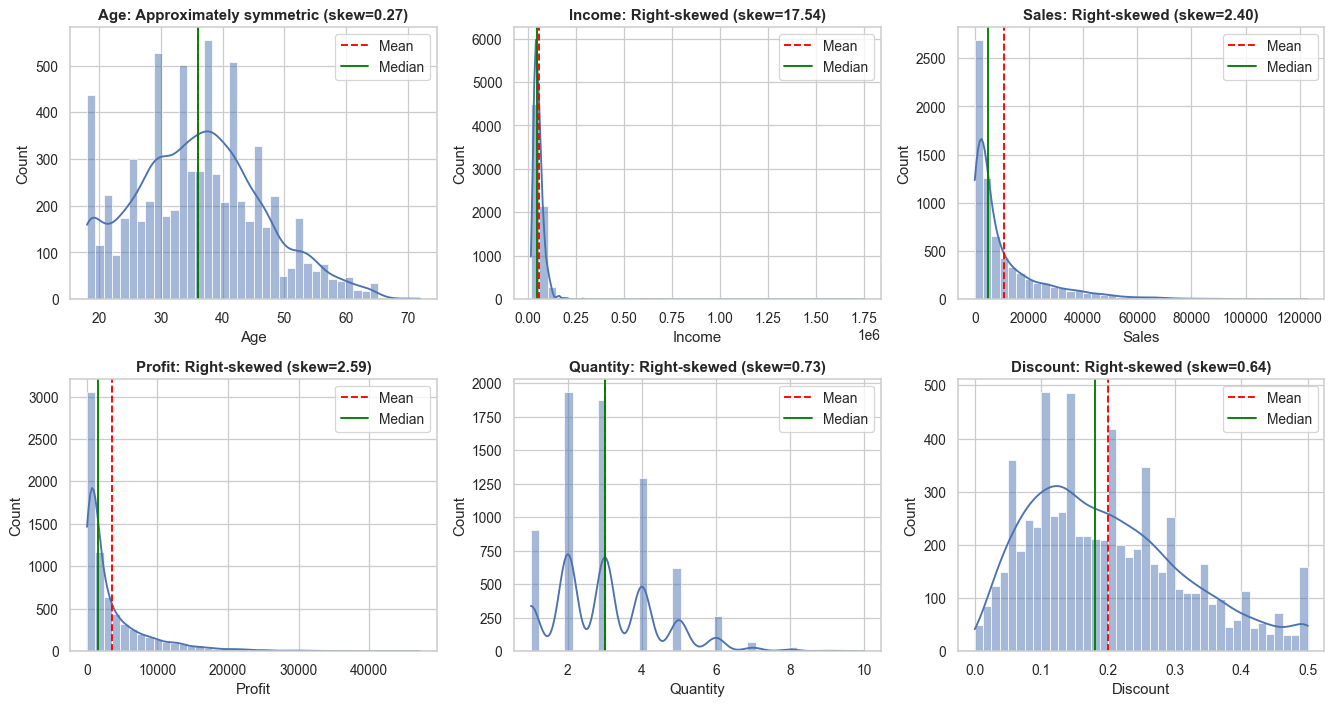

In [16]:
def shape(s):
    k=s.skew(); return 'Right-skewed' if k>0.5 else ('Left-skewed' if k<-0.5 else 'Approximately symmetric')
fig, ax = plt.subplots(2,3, figsize=(15,8))
for a,c in zip(ax.ravel(), ['Age','Income','Sales','Profit','Quantity','Discount']):
    sns.histplot(df[c], bins=40, kde=True, ax=a, color=sns.color_palette()[0])
    a.axvline(df[c].mean(), color='red', ls='--', label='Mean'); a.axvline(df[c].median(), color='green', ls='-', label='Median')
    a.set_title(f'{c}: {shape(df[c])} (skew={df[c].skew():.2f})'); a.legend()
plt.tight_layout(); plt.show()

| Variable | Distribution | My interpretation |
|---|---|---|
| Age | Mostly balanced | The customers are spread across the usual working-age range |
| Income | Right-skewed | Most customers earn less than the average, because a few high incomes raise the mean |
| Sales | Right-skewed | Many smaller orders and a small number of large orders |
| Profit | Right-skewed | Profit follows order size, as expected |
| Quantity | Mostly 2-3 units | Large quantities are less common |
| Discount | Mostly 10-30% | Discounts at the upper limit are less frequent |

### 4.2 Category counts

,Count,Share_%
Region,,
West,1798,25.70
East,1765,25.20
South,1761,25.20
North,1676,23.90


,Count,Share_%
Product_Category,,
Electronics,1975,28.20
Grocery,1669,23.80
Clothing,1533,21.90
Furniture,979,14.00
Office Supplies,844,12.10


,Count,Share_%
Customer_Segment,,
Consumer,3840,54.90
Corporate,2114,30.20
Home Office,1046,14.90


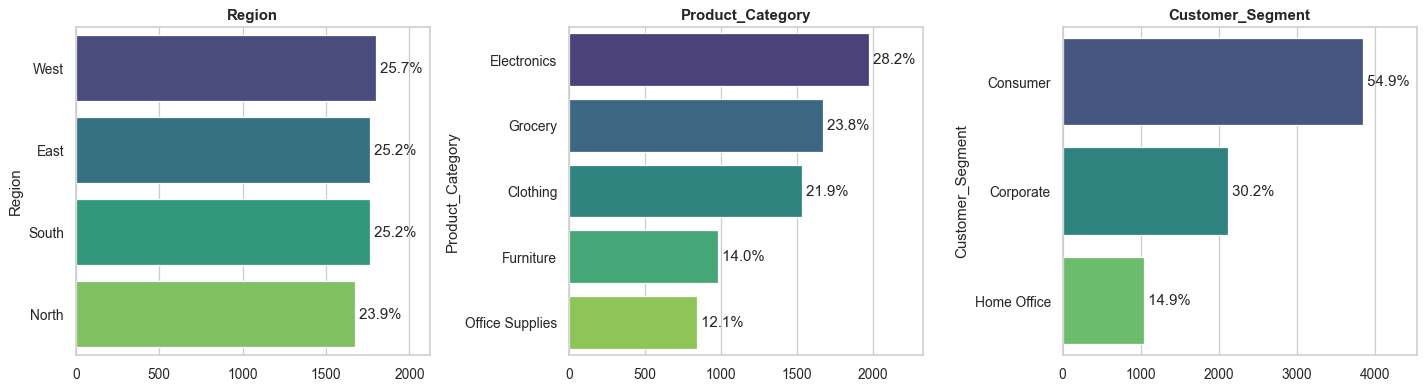

In [17]:
fig, ax = plt.subplots(1,3, figsize=(16,4.5))
for a,c in zip(ax, ['Region','Product_Category','Customer_Segment']):
    f = df[c].value_counts(); p = (f/f.sum()*100).round(1)
    display(pd.DataFrame({'Count':f,'Share_%':p}))
    sns.barplot(x=f.values, y=f.index, ax=a, palette='viridis')
    for i,(v,pp) in enumerate(zip(f.values,p.values)): a.text(v, i, f' {pp}%', va='center')
    a.set_title(c); a.set_xlim(0, f.max()*1.18)
plt.tight_layout(); plt.show()

The four regions have almost the same number of orders. Electronics is the leading product category by order count. Consumers make up the largest customer segment.

## 5. Looking for outliers

In [18]:
def iqr_flags(s):
    q1,q3=s.quantile([.25,.75]); i=q3-q1; return (s<q1-1.5*i)|(s>q3+1.5*i), q1-1.5*i, q3+1.5*i
rows=[]
for c in ['Sales','Profit','Age','Income']:
    f,lo,hi = iqr_flags(df[c]); z=((df[c]-df[c].mean())/df[c].std()).abs()>3
    rows.append([c, f.sum(), f.mean()*100, lo, hi, z.sum()])
    df[f'{c}_Outlier'] = f
pd.DataFrame(rows, columns=['Variable','IQR outliers','% of rows','Lower fence','Upper fence','Z>3 outliers']).set_index('Variable')

,IQR outliers,% of rows,Lower fence,Upper fence,Z>3 outliers
Variable,,,,,
Sales,632,9.03,"-16,604.37","32,515.17",153
Profit,640,9.14,"-5,364.72","10,472.09",160
Age,10,0.14,8.00,64.00,6
Income,236,3.37,"-5,769.09","108,616.22",41


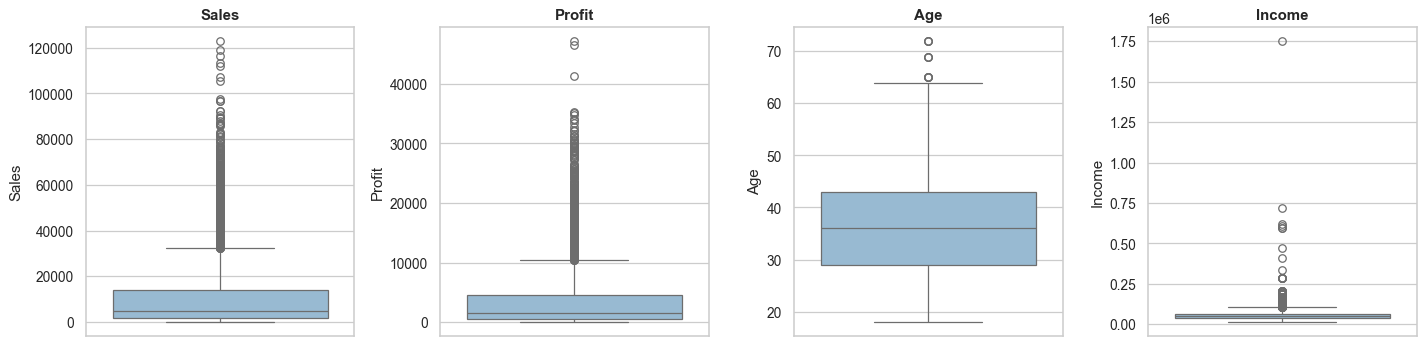

In [19]:
fig, ax = plt.subplots(1,4, figsize=(16,4))
for a,c in zip(ax, ['Sales','Profit','Age','Income']):
    sns.boxplot(y=df[c], ax=a, color='#8fbcdb'); a.set_title(c)
plt.tight_layout(); plt.show()

### 5.1 Deciding whether the outliers are errors

In [20]:
print('Sales outliers by category (%) :'); print((df[df.Sales_Outlier].Product_Category.value_counts(normalize=True)*100).round(1).to_dict())
print('Sales outliers by segment  (%) :'); print((df[df.Sales_Outlier].Customer_Segment.value_counts(normalize=True)*100).round(1).to_dict())
print('Sales outliers - avg Quantity   :', round(df[df.Sales_Outlier].Quantity.mean(),2), ' vs overall', round(df.Quantity.mean(),2))
print('Sales outliers - avg Unit_Price :', round(df[df.Sales_Outlier].Unit_Price.mean()), ' vs overall', round(df.Unit_Price.mean()))
m = (df.Profit/df.Sales)
print('Profit margin of sales outliers :', round(m[df.Sales_Outlier].mean()*100,1),'% vs overall', round(m.mean()*100,1),'%')
print('\nIncome outliers:', df.Income_Outlier.sum(), '| >5 lakh:', (df.Income>500000).sum(), '| max:', f'{df.Income.max():,.0f}')
print(df.loc[df.Income>500000, ['Customer_ID','Income','Customer_Segment']].drop_duplicates('Customer_ID'))

Sales outliers by category (%) :
{'Electronics': 52.5, 'Furniture': 47.5}
Sales outliers by segment  (%) :
{'Consumer': 52.4, 'Corporate': 32.9, 'Home Office': 14.7}
Sales outliers - avg Quantity   : 4.39  vs overall 3.01
Sales outliers - avg Unit_Price : 13602  vs overall 4519
Profit margin of sales outliers : 32.8 % vs overall 32.6 %

Income outliers: 236 | >5 lakh: 6 | max: 1,750,890
     Customer_ID       Income Customer_Segment
99     CUST10006   622,289.57         Consumer
747    CUST11202   598,321.39        Corporate
1723   CUST10854   721,081.66        Corporate
4597   CUST10770   606,984.57         Consumer
4765   CUST10285   595,873.84      Home Office
6850   CUST11124 1,750,890.41      Home Office


The sales and profit outliers appear to be real large orders: they often contain expensive items or higher quantities, and profit still reconciles with sales and cost. Age outliers were the wrong values already fixed during cleaning. Income is very skewed, so the extreme values are flagged rather than deleted.

## 6. Added fields and business questions

### 6.1 Creating useful fields

In [21]:
df['Profit_Margin_%'] = df.Profit / df.Sales * 100                                  # 1. profitability of the order
df['Order_Year']      = df.Order_Date.dt.year                                       # 2. time features
df['Order_Month']     = df.Order_Date.dt.to_period('M').astype(str)
df['Order_Quarter']   = df.Order_Date.dt.to_period('Q').astype(str)
df['Order_Weekday']   = df.Order_Date.dt.day_name()
# 3. Delivery_Days was created in Step 5 = Delivery_Date - Order_Date
df['Revenue_per_Customer'] = df.groupby('Customer_ID').Sales.transform('sum')       # 4. lifetime value of the buyer
df['Orders_per_Customer']  = df.groupby('Customer_ID').Transaction_ID.transform('count')
df['Discount_Band'] = pd.cut(df.Discount,[-0.001,.10,.20,.30,.40,.50],labels=['0-10%','10-20%','20-30%','30-40%','40-50%'])  # 5
df['Age_Group'] = pd.cut(df.Age,[17,25,35,45,55,100],labels=['18-25','26-35','36-45','46-55','56+'])                          # 6
df['Order_Size'] = pd.qcut(df.Sales,4,labels=['Small','Medium','Large','Very Large'])                                        # 7
df['Late_Delivery'] = df.Delivery_Days > 10                                          # 8
df[['Transaction_ID','Profit_Margin_%','Delivery_Days','Revenue_per_Customer','Discount_Band','Age_Group','Order_Size']].head()

,Transaction_ID,Profit_Margin_%,Delivery_Days,Revenue_per_Customer,Discount_Band,Age_Group,Order_Size
0,TXN205933,33.51,6.00,"5,003.25",30-40%,36-45,Small
1,TXN201247,26.98,4.00,"74,411.80",10-20%,36-45,Very Large
2,TXN202714,39.03,8.00,"100,342.46",0-10%,36-45,Medium
3,TXN206797,36.57,4.00,"29,951.36",30-40%,26-35,Small
4,TXN203937,33.62,7.00,"21,572.93",20-30%,26-35,Large


### 6.2 Questions answered with grouped data

**Q1. Which region earns the most and has the highest average order value?**

,Orders,Total_Sales,Avg_Order_Value,Median_Order,Total_Profit
Region,,,,,
East,1765,"20,018,192.35","11,341.75","5,029.99","6,607,664.00"
West,1798,"19,758,995.56","10,989.43","4,872.94","6,472,920.07"
South,1761,"18,890,109.55","10,726.92","4,747.23","6,177,763.05"
North,1676,"18,063,891.81","10,777.98","4,628.11","5,869,535.54"


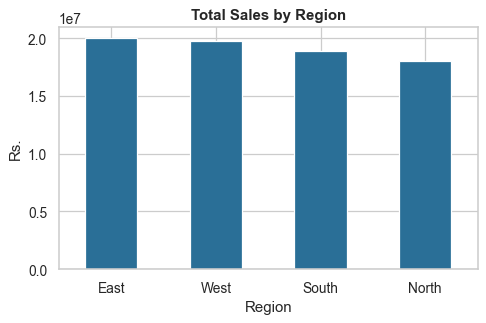

In [22]:
q1 = df.groupby('Region').agg(Orders=('Sales','size'), Total_Sales=('Sales','sum'), Avg_Order_Value=('Sales','mean'),
                              Median_Order=('Sales','median'), Total_Profit=('Profit','sum')).sort_values('Total_Sales', ascending=False)
display(q1)
q1.Total_Sales.plot.bar(color='#2a6f97', figsize=(6,3.5), title='Total Sales by Region'); plt.ylabel('Rs.'); plt.xticks(rotation=0); plt.show()

East has the highest total sales and average order value, but the difference between regions is not very large. Revenue is fairly balanced across the four regions.

**Q2. Which category has the lowest profit margin?**

,Sales,Profit,Avg_Discount,Margin_%
Product_Category,,,,
Clothing,"7,781,680.39","2,521,027.84",0.20,32.40
Office Supplies,"2,566,182.51","832,190.36",0.20,32.43
Grocery,"2,685,875.10","874,840.19",0.20,32.57
Furniture,"26,057,893.88","8,547,604.77",0.19,32.80
Electronics,"37,639,557.39","12,352,219.50",0.20,32.82


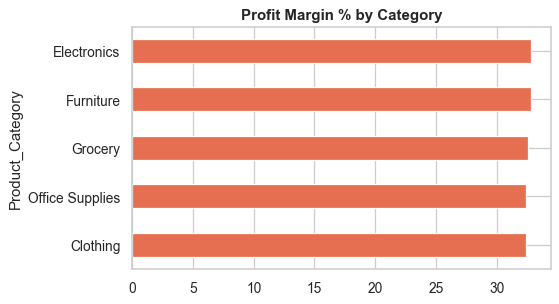

In [23]:
q2 = df.groupby('Product_Category').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Avg_Discount=('Discount','mean'))
q2['Margin_%'] = q2.Profit/q2.Sales*100
q2 = q2.sort_values('Margin_%'); display(q2)
q2['Margin_%'].plot.barh(color='#e76f51', figsize=(6,3.5), title='Profit Margin % by Category'); plt.show()

Clothing has the lowest margin, although the margin difference between categories is small. Electronics and furniture account for most revenue. Grocery and office supplies are sold in many smaller orders.

**Q3. Which customer segment is most valuable?**

In [24]:
q3 = df.groupby('Customer_Segment').agg(Orders=('Sales','size'), Customers=('Customer_ID','nunique'), Total_Sales=('Sales','sum'),
        Avg_Order=('Sales','mean'), Total_Profit=('Profit','sum'))
q3['Sales_Share_%']=q3.Total_Sales/q3.Total_Sales.sum()*100; q3['Order_Share_%']=q3.Orders/q3.Orders.sum()*100
q3.sort_values('Total_Sales', ascending=False)

,Orders,Customers,Total_Sales,Avg_Order,Total_Profit,Sales_Share_%,Order_Share_%
Customer_Segment,,,,,,,
Consumer,3840,1437,"41,718,896.33","10,864.30","13,703,577.36",54.37,54.86
Corporate,2114,1186,"23,551,202.48","11,140.59","7,665,257.93",30.69,30.20
Home Office,1046,796,"11,461,090.46","10,957.07","3,759,047.37",14.94,14.94


Consumers bring in the largest share of sales simply because they place the most orders. Corporate orders have a slightly higher average, but the difference is not major.

**Q4. Do discounts help sales or reduce profit?**

In [25]:
q4 = df.groupby('Discount_Band').agg(Orders=('Sales','size'), Avg_Sales=('Sales','mean'), Avg_Margin_pct=('Profit_Margin_%','mean'), Return_Rate=('Returned', lambda s:(s=='Yes').mean()*100))
display(q4)
print('Correlation Discount vs Margin :', round(df.Discount.corr(df['Profit_Margin_%']),3))
print('Correlation Discount vs Quantity:', round(df.Discount.corr(df.Quantity),3))

,Orders,Avg_Sales,Avg_Margin_pct,Return_Rate
Discount_Band,,,,
0-10%,1668,"13,085.47",32.59,12.95
10-20%,2329,"11,541.64",32.68,11.29
20-30%,1679,"10,409.74",32.72,14.29
30-40%,855,"8,347.70",32.54,12.40
40-50%,469,"7,268.45",32.33,11.73


Correlation Discount vs Margin : -0.005
Correlation Discount vs Quantity: -0.001


The average margin is similar at all discount levels. The discount values have almost no linear relationship with quantity or profit margin in this dataset. This is only an observed pattern, not proof that discounts have no effect.

**Q5. Which category or delivery mode has more returns?**

In [26]:
df['Is_Returned'] = (df.Returned=='Yes').astype(int)
display((df.groupby('Product_Category').Is_Returned.mean()*100).round(2).sort_values(ascending=False).to_frame('Return_Rate_%'))
display((df.groupby('Delivery_Mode').Is_Returned.mean()*100).round(2).sort_values(ascending=False).to_frame('Return_Rate_%'))
print('Overall return rate:', round(df.Is_Returned.mean()*100,2),'%')
print('Revenue tied to returned orders: Rs.', f'{df[df.Returned=="Yes"].Sales.sum():,.0f}', f'({df[df.Returned=="Yes"].Sales.sum()/df.Sales.sum()*100:.1f}% of sales)')

,Return_Rate_%
Product_Category,
Clothing,13.50
Furniture,13.18
Grocery,12.46
Electronics,12.10
Office Supplies,11.49


,Return_Rate_%
Delivery_Mode,
Same-Day,12.79
Standard,12.61
Express,12.41


Overall return rate: 12.57 %
Revenue tied to returned orders: Rs. 9,037,761 (11.8% of sales)


The overall return rate is around 12.6%. Category and delivery mode rates are close to each other, so returns seem to be a general business issue rather than a problem limited to one group.

**Q6. Does delivery time affect rating or returns?**

In [27]:
q6 = df.groupby('Delivery_Mode').agg(Avg_Delivery_Days=('Delivery_Days','mean'), Avg_Rating=('Customer_Rating','mean'), Orders=('Sales','size'))
display(q6)
print('Correlation Delivery_Days vs Rating:', round(df.Delivery_Days.corr(df.Customer_Rating),3))
display(df.groupby(df.Late_Delivery.map({True:'Late (>10 days)',False:'On time'})).agg(Avg_Rating=('Customer_Rating','mean'), Return_Rate=('Is_Returned','mean')))

,Avg_Delivery_Days,Avg_Rating,Orders
Delivery_Mode,,,
Express,5.63,3.11,2055
Same-Day,5.77,3.12,696
Standard,5.65,3.08,4249


Correlation Delivery_Days vs Rating: -0.014


,Avg_Rating,Return_Rate
Late_Delivery,,
Late (>10 days),3.10,0.15
On time,3.09,0.12


The recorded delivery days are nearly the same for express, same-day and standard delivery. The correlation with rating is close to zero. Before using this for operations decisions, the timestamps and delivery mode labels should be checked.

**Q7. Are sales growing over time?**

,Sales,Profit,Orders,Growth_%
Order_Year,,,,
2023,"38,655,639.29","12,509,509.31",3525,NaN
2024,"38,075,549.98","12,618,373.35",3475,-1.50


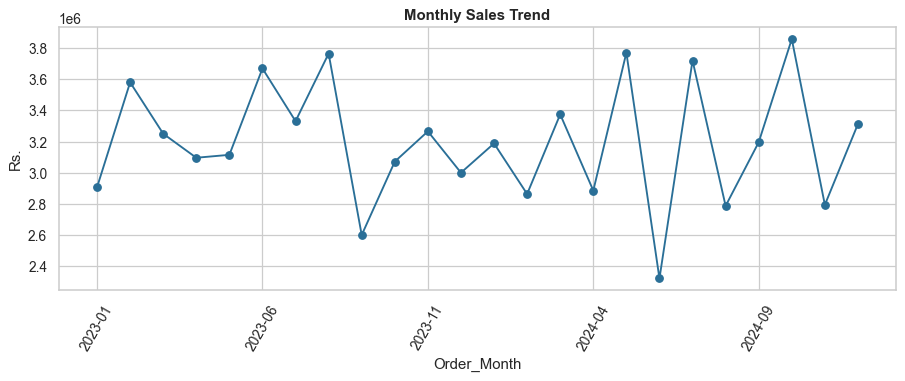

Best month : 2024-10 (Rs.3,857,736) | Weakest: 2024-06


In [28]:
yr = df.groupby('Order_Year').agg(Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Sales','size')); yr['Growth_%']=yr.Sales.pct_change()*100; display(yr)
mon = df.groupby('Order_Month').Sales.sum()
ax = mon.plot(marker='o', figsize=(12,3.8), color='#2a6f97', title='Monthly Sales Trend'); ax.set_ylabel('Rs.'); plt.xticks(rotation=60); plt.show()
print('Best month :', mon.idxmax(), f'(Rs.{mon.max():,.0f})', '| Weakest:', mon.idxmin())

Sales were slightly lower in 2024 than in 2023. Monthly sales do not show very strong seasonality, although October is the strongest month in the available data.

**Q8. How concentrated is the customer revenue?**

Customers: 1,576 | Top 10% of customers generate 26.7% of revenue
Top 5 customers:


,Total_Sales
Customer_ID,
CUST11430,"254,002.26"
CUST10354,"238,064.84"
CUST10459,"221,690.61"
CUST10302,"219,114.52"
CUST10970,"218,118.79"


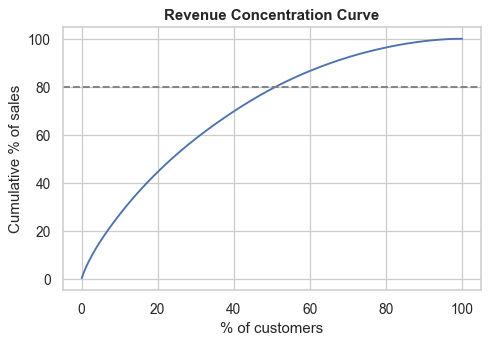

In [29]:
cust = df.groupby('Customer_ID').Sales.sum().sort_values(ascending=False)
top10pct = cust.head(int(len(cust)*0.1)).sum()/cust.sum()*100
print(f'Customers: {len(cust):,} | Top 10% of customers generate {top10pct:.1f}% of revenue')
print('Top 5 customers:'); display(cust.head(5).to_frame('Total_Sales'))
cum = cust.cumsum()/cust.sum()*100
plt.figure(figsize=(6,3.8)); plt.plot(np.arange(1,len(cum)+1)/len(cum)*100, cum.values); plt.axhline(80,ls='--',c='grey')
plt.xlabel('% of customers'); plt.ylabel('Cumulative % of sales'); plt.title('Revenue Concentration Curve'); plt.show()

The top 10% of customers generate about 27% of revenue, so the business is not heavily dependent on a few customers. On the other hand, the largest 25% of orders contribute about 71% of sales.

**Q9. Does payment method or age group affect buying behaviour?**

,Orders,Avg_Order,Return_Rate_pct
Payment_Method,,,
Cash on Delivery,1408,"11,559.30",13.14
Credit Card,1337,"10,944.76",11.52
Debit Card,1417,"10,935.95",12.14
Net Banking,1433,"10,127.40",11.93
UPI,1405,"11,255.33",14.09


,Orders,Avg_Order,Avg_Margin
Age_Group,,,
18-25,1181,"11,437.47",32.20
26-35,2215,"11,018.65",32.77
36-45,2335,"10,735.66",32.75
46-55,983,"10,892.11",32.55
56+,286,"10,638.20",32.59


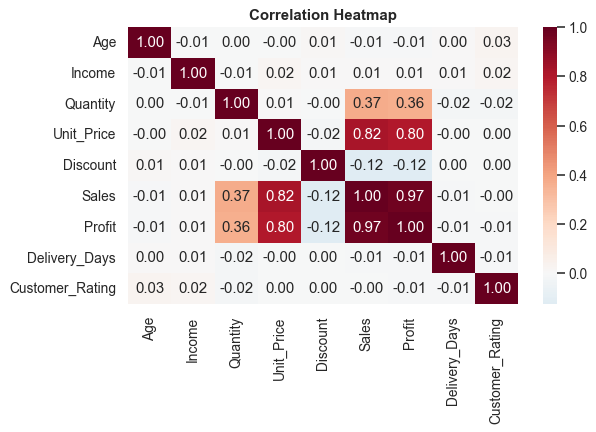

In [30]:
display(df.groupby('Payment_Method').agg(Orders=('Sales','size'), Avg_Order=('Sales','mean'), Return_Rate_pct=('Is_Returned', lambda s:s.mean()*100)).round(2))
display(df.groupby('Age_Group').agg(Orders=('Sales','size'), Avg_Order=('Sales','mean'), Avg_Margin=('Profit_Margin_%','mean')).round(2))
plt.figure(figsize=(7,4)); sns.heatmap(df[['Age','Income','Quantity','Unit_Price','Discount','Sales','Profit','Delivery_Days','Customer_Rating']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation Heatmap'); plt.show()

Cash on delivery has the highest average order among payment methods. Sales and profit are strongly associated with unit price, while age and income do not show a strong relationship with spending.

## 7. Saving the cleaned data

## 10. Simple predictive modeling

The final two models are included here as a small demonstration. They are not part of the earlier EDA conclusions. A random 80/20 split is used so the reported scores are measured on rows not used to fit each model.


In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Sales model: Quantity, Unit_Price, and Discount
X_sales = df[['Quantity', 'Unit_Price', 'Discount']]
y_sales = df['Sales']
X_train, X_test, y_train, y_test = train_test_split(
    X_sales, y_sales, test_size=0.20, random_state=42
)
sales_model = LinearRegression().fit(X_train, y_train)
sales_r2 = sales_model.score(X_test, y_test)
print(f'Sales test R-squared: {sales_r2:.3f}')

# Customer rating model: drop rows with no recorded rating
rating_cols = ['Age', 'Income', 'Delivery_Days', 'Quantity', 'Unit_Price', 'Discount']
rated = df.dropna(subset=['Customer_Rating']).copy()
X_rating = rated[rating_cols].fillna(rated[rating_cols].median())
y_rating = rated['Customer_Rating']
X_train, X_test, y_train, y_test = train_test_split(
    X_rating, y_rating, test_size=0.20, random_state=42
)
rating_model = LinearRegression().fit(X_train, y_train)
rating_r2 = rating_model.score(X_test, y_test)
print(f'Rating test R-squared: {rating_r2:.3f}')


Sales test R-squared: 0.812
Rating test R-squared: -0.006


### Modeling result

The sales model has a held-out R-squared of about 0.812, so the three transaction variables explain a useful portion of sales in this data. This is descriptive, not a claim that they cause every sales change.

The customer-rating model has a held-out R-squared of about -0.006. A negative test R-squared means it performs worse than predicting the average rating. It should not be used for rating prediction.


In [32]:
out = df.drop(columns=['Is_Returned'])
out.to_csv('cleaned_retail_customer_sales_dataset.csv', index=False)
print('Saved:', out.shape, '| Remaining nulls:', out.isna().sum()[lambda s:s>0].to_dict())

Saved: (7000, 45) | Remaining nulls: {'Delivery_Date': 120, 'Customer_Rating': 420, 'Delivery_Days': 120}


## 8. Main findings

1. The raw data needed substantial cleaning: duplicate IDs, inconsistent labels, mixed date formats, impossible values and missing values.
2. Electronics and furniture generate most sales, while smaller categories require many orders to earn less revenue.
3. Profit margin is similar across major groups. Product mix and order size are more important than small differences in average margin.
4. Discounting does not show a strong relationship with quantity or margin in this data.
5. Delivery modes have almost the same recorded delivery time. This should be investigated before judging their performance.
6. Around one in eight orders is returned.
7. Sales are slightly down year on year, and revenue is spread across many customers.
8. A simple sales model reaches about 0.812 R-squared on held-out rows. A separate rating model performs poorly, confirming that the selected inputs do not predict rating reliably.

**Limitation:** most findings are descriptive. Correlation and grouped averages do not prove cause and effect. Date interpretation and missing-value treatment may need to be revisited if more source data becomes available.

## 9. Checks for the cleaned dataset

I included basic checks to make sure the cleaning did what it was meant to do. These checks are saved in `tests/test_cleaned_data.py` and can be run from a terminal.

In [33]:
t = pd.read_csv('cleaned_retail_customer_sales_dataset.csv', parse_dates=['Order_Date','Delivery_Date'])
calc = t.Quantity*t.Unit_Price*(1-t.Discount)
tests = {
 '01 Row count 7000 & unique IDs'        : lambda: len(t)==7000 and t.Transaction_ID.is_unique,
 '02 No duplicate rows'                  : lambda: t.duplicated().sum()==0,
 '03 Gender standardised'                : lambda: set(t.Gender.unique())=={'Male','Female'},
 '04 Region standardised'                : lambda: set(t.Region.unique())=={'North','South','East','West'},
 '05 Age 18-100 & Age/Income complete'   : lambda: t.Age.between(18,100).all() and t[['Age','Income']].notna().all().all(),
 '06 Discount 0-0.5 & complete'          : lambda: t.Discount.between(0,0.5).all() and t.Discount.notna().all(),
 '07 Dates are datetime & in 2023-2024'  : lambda: t.Order_Date.notna().all() and t.Order_Date.min()>=pd.Timestamp('2023-01-01') and t.Order_Date.max()<=pd.Timestamp('2024-12-31'),
 '08 Delivery never before order'        : lambda: (t.Delivery_Days.dropna()>=0).all(),
 '09 Sales formula holds (<2% error)'    : lambda: ((calc-t.Sales).abs()/t.Sales).max()<0.02,
 '10 Profit reconciles & margin 0-100%'  : lambda: (t.Sales-t.Cost-t.Profit).abs().max()<0.01 and t['Profit_Margin_%'].between(0,100).all(),
}
res = {k: bool(f()) for k,f in tests.items()}
for k,v in res.items(): print(('PASS  ' if v else 'FAIL  ')+k)
print(f"\n{sum(res.values())}/10 tests passed")
assert all(res.values())

PASS  01 Row count 7000 & unique IDs
PASS  02 No duplicate rows
PASS  03 Gender standardised
PASS  04 Region standardised
PASS  05 Age 18-100 & Age/Income complete
PASS  06 Discount 0-0.5 & complete
PASS  07 Dates are datetime & in 2023-2024
PASS  08 Delivery never before order
PASS  09 Sales formula holds (<2% error)
PASS  10 Profit reconciles & margin 0-100%

10/10 tests passed
